In [1]:
from utils.calibration import CalibrationSignal
from utils.imu_data import IMUData
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
from geopy.distance import geodesic
iq0_path ='/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_03_51_14_freq_11_325G_bw_2.0M_ts_1709697074.3228533_inrx0.dat'
imu_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_03_50_54.txt'
date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = float(iq0_path.split('_')[-2])
fc = 11.325e9
sample_rate = 2e6

imu = IMUData(imu_path)
imu_data = imu.read_imu_data()
lat, lon, alt = imu.get_latlonalt_()
lat_gt, lon_gt, alt_gt = np.mean(lat), np.mean(lon), np.mean(alt)
print('ground truth lat, lon, alt: ', lat_gt, lon_gt, alt_gt)

ground truth lat, lon, alt:  40.11614836511319 -88.22277704066285 191.91835843704916


In [2]:
def ned2latlon(azimuth, distance, lat, lon):
    '''
    Calculate destination coordinates 1 km away
    azimuth: degrees
    distance: meters
    lat, lon: degrees
    '''
    
    destination_coordinates = geodesic(meters=distance).destination((lat, lon), azimuth)

    return destination_coordinates.latitude, destination_coordinates.longitude


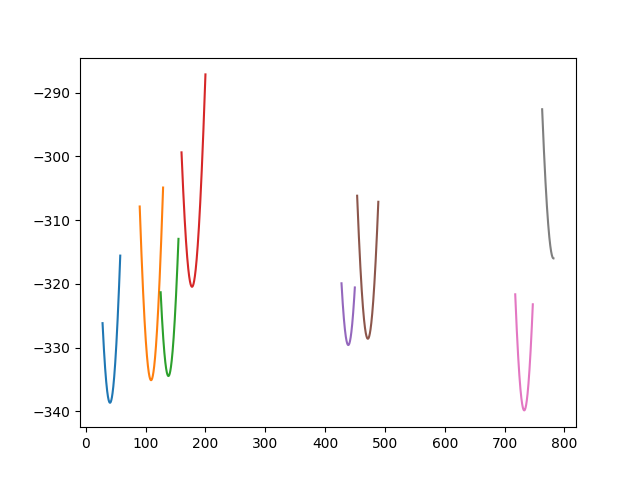

In [6]:
from sat_id import dopp_sim_1_sat
dopp_track_main_dict = sio.loadmat(date+'/doppler_track.mat')['dopp_track_main_dict']
freq_offset = sio.loadmat(date+'/doppler_track.mat')['freq_offset'][:,0]
num_sats = len(freq_offset)
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']

t_sim_list, dopp_gt_list, az_gt_list, el_gt_list, range_gt_list, p_list = [], [], [], [], [], []
%matplotlib widget
plt.clf()
for sat_idx in range(num_sats):
    dopp_track = dopp_track_main_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)
    # plt.scatter(t_repeat, dopp_repeat+freq_offset[sat_idx], marker='.')
    # polynomial fit the doppler
    p = np.polyfit(t_repeat, dopp_repeat+freq_offset[sat_idx], 3, w=np.abs(dopp_track[:, 2]))
    # plt.plot(t_repeat, dopp_repeat+freq_offset[sat_idx], '.', markersize=2)
    # p = np.polyfit(t_repeat, dopp_repeat, 3, w=np.abs(dopp_track[:, 2]))
    # plt.plot(t_repeat, dopp_repeat, '.', markersize=2)
    # plt.plot(np.arange(t_sat_start, t_sat_end, .1), np.polyval(p, np.arange(t_sat_start, t_sat_end, .1)), '--')
    
    t_sim, dopp_gt, az_gt, el_gt, range_gt = dopp_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, lat_gt, lon_gt, alt_gt)
    t_sim += t_sat_start

    t_sim_list.append(t_sim)
    dopp_gt_list.append(dopp_gt)
    az_gt_list.append(np.deg2rad(az_gt))
    el_gt_list.append(np.deg2rad(el_gt))
    range_gt_list.append(range_gt)
    p_list.append(p)
    plt.plot(t_sim[0:-1], np.diff(dopp_gt))
plt.show()

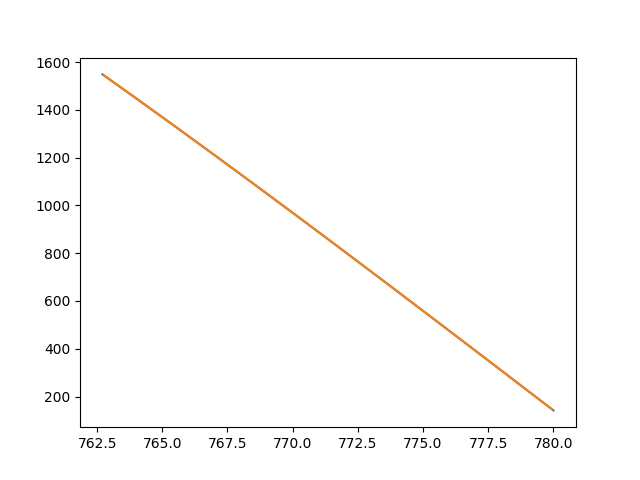

In [9]:
%matplotlib widget
c = 299792458
range_rate = dopp_gt * c / fc
plt.clf()
plt.plot(t_sim, range_rate)
plt.plot(t_sim[0:-1]+0.05, -np.diff(range_gt)/np.diff(t_sim))
plt.show()

In [66]:
from scipy.optimize import least_squares
# column stack all of the range, az, el
# range_gt_all = np.hstack(range_gt_list)
# az_gt_all = np.hstack(az_gt_list)
# el_gt_all = np.hstack(el_gt_list)
# loc_sat = np.column_stack((range_gt_all * np.cos(el_gt_all) * np.sin(az_gt_all), range_gt_all * np.cos(el_gt_all) * np.cos(az_gt_all), range_gt_all * np.sin(el_gt_all)))
t_step = t_sim[1]-t_sim[0]
loc_sat_list, dopp_gt_list = [], []
for sat_idx in range(num_sats):
    range_gt, az_gt, el_gt = range_gt_list[sat_idx], az_gt_list[sat_idx], el_gt_list[sat_idx]
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt))) 
    loc_sat_list.append(loc_sat)

    p = p_list[sat_idx]
    t_sim = t_sim_list[sat_idx]
    dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2))

def residual(params, loc_sat_list, dopp_gt_list, fc, t_step):
    c = 299792458
    x, y = params[0], params[1]
    num_sats = len(loc_sat_list)
    loc_rx = np.array([x, y, 0])
    err = 0
    for sat_idx in range(num_sats):
        loc_sat = loc_sat_list[sat_idx]
        dopp_gt = dopp_gt_list[sat_idx]
        the_range = np.linalg.norm(loc_sat-loc_rx, axis=1)
        the_range_rate = np.diff(the_range)/t_step
        dopp = -the_range_rate * fc / c + params[2+sat_idx]
        err += np.linalg.norm(dopp-dopp_gt)
    return err
np.random.seed(42)
initial_guess = [2e3, 2e3, 0, 0, 0, 0, 0, 0, 0, 0]
# parameter_bounds = ([-100e3, -100e3], [100e3, 100e3])
result = least_squares(residual, initial_guess, args=(loc_sat_list, dopp_gt_list, fc, t_step))

In [ ]:
from scipy.optimize import brute
t_step = t_sim[1]-t_sim[0]
loc_sat_list, dopp_gt_list = [], []
for sat_idx in range(num_sats):
    range_gt, az_gt, el_gt = range_gt_list[sat_idx], az_gt_list[sat_idx], el_gt_list[sat_idx]
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt))) 
    loc_sat_list.append(loc_sat)

    p = p_list[sat_idx]
    t_sim = t_sim_list[sat_idx]
    dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2))

def residual(params, loc_sat_list, dopp_gt_list, fc, t_step):
    c = 299792458
    x, y = params[0], params[1]
    num_sats = len(loc_sat_list)
    loc_rx = np.array([x, y, 0])
    err = 0
    for sat_idx in range(num_sats):
        loc_sat = loc_sat_list[sat_idx]
        dopp_gt = dopp_gt_list[sat_idx]
        the_range = np.linalg.norm(loc_sat-loc_rx, axis=1)
        the_range_rate = np.diff(the_range)/t_step
        dopp = -the_range_rate * fc / c + params[2+sat_idx]
        err += np.linalg.norm(dopp-dopp_gt)
    return err
np.random.seed(42)
initial_guess = [2e3, 2e3, 0, 0, 0, 0, 0, 0, 0, 0]
# parameter_bounds = ([-100e3, -100e3], [100e3, 100e3])
result = brute(residual, initial_guess, args=(loc_sat_list, dopp_gt_list, fc, t_step))

In [67]:
print(result.x[0:2])
print(np.linalg.norm(result.x[0:2]))

[1932.46783948 1484.01983702]
2436.5440335172134


In [5]:
from tqdm import tqdm

# plt.clf()
lat, lon, alt = lat_gt, lon_gt, alt_gt

t_step = .1

x_grid, y_grid = np.linspace(-5e3, 5e3, 10), np.linspace(-5e3, 5e3, 10)
err_min = np.inf
num_sat_for_training = 1
for x in tqdm(x_grid):
    for y in y_grid:
        lat_, lon_ = ned2latlon(0, y, lat_gt, lon_gt)
        lat, lon = ned2latlon(90, x, lat_, lon_)
        dopp_err, num_t_step = 0, 0
        for sat_idx in range(num_sats):
            dopp_track = dopp_track_main_dict[0, sat_idx]
            t_repeat = dopp_track[:, 0].real
            dopp_repeat = dopp_track[:, 1].real
            t_sat_start, t_sat_end = t_repeat[0], t_repeat[-1]
            # plt.scatter(t_repeat, dopp_repeat+freq_offset[sat_idx], marker='.')
            # polynomial fit the doppler
            # p = np.polyfit(t_repeat, dopp_repeat+freq_offset[sat_idx], 2, w=np.abs(dopp_track[:, 2]))
            p = np.polyfit(t_repeat, dopp_repeat+freq_offset[sat_idx], 3)

            t_sim, dopp_gt, _, _, _ = dopp_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, t_step, lat, lon, alt)
            t_sim += t_sat_start
            # plt.plot(t_sim[0:-1], np.diff(np.polyval(p, t_sim))/t_step)
            # plt.plot(t_sim[0:-1], np.diff(dopp_gt)/t_step, '--')
            # plt.plot(t_sim, np.polyval(p, t_sim))
            # plt.plot(t_sim, dopp_gt, '--')

            dopp_err += np.sum(np.abs(np.polyval(p, t_sim)-dopp_gt))
            # dopp_err += np.sum(np.abs(np.diff(np.polyval(p, t_sim))-np.diff(dopp_gt)))
            # num_t_step += len(t_sim)
        # plt.show()
        if dopp_err < err_min:
            err_min = dopp_err
            x_min, y_min = x, y
# print('dopp_err: ', dopp_err/num_t_step)

  0%|          | 0/10 [00:06<?, ?it/s]


KeyboardInterrupt: 

In [18]:
y_min

-555.5555555555557